# Lab 2 – How a computer sees an animal, and the classifier zoo
*Session 3 · about 2 hours (computing the CNN features takes ~15 min on a 4-core laptop, a few minutes on a Colab GPU)*

The same classifier can be excellent or useless depending on the numbers we give it. Today we compare three
ways to describe a crop, and seven classifiers on each.

| feature set | numbers per crop | idea |
|---|---|---|
| `pixels` | 768 | the crop shrunk to 16 × 16 pixels × 3 colours |
| `colour_stats` | 30 | hand-made characters: colour, brightness, texture, hue histogram (Lab 1) |
| `cnn` | 512 | what a **convolutional neural network** pre-trained on 1.2 million everyday photos (ImageNet) "sees" |

In [1]:
# Run this cell first. On Google Colab it fetches the course; on your own computer it only loads the data.
import os, subprocess, sys
from pathlib import Path
if "google.colab" in sys.modules:
    if not Path("/content/fathomnetchallange").exists():
        if Path("/content/fathomnetchallange.zip").exists():      # zip from your tutor (drag it into Files)
            subprocess.run(["unzip", "-q", "/content/fathomnetchallange.zip", "-d", "/content"], check=True)
        else:
            subprocess.run(["git", "clone", "-q", "https://github.com/TorbenGl/fathomnetchallange",
                            "/content/fathomnetchallange"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-learn", "fathomnet"], check=True)
    os.chdir("/content/fathomnetchallange/course")
sys.path.insert(0, str(Path.cwd()))

from setup_env import setup
ROOT = setup()          # first time: downloads the crops (~15 min). setup(per_category=100) is a quick subset.

import warnings; warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from classifier_lab import data, features, models, evaluate
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

Dataset ready: /home/user/fathomnetchallange/fathomnet2025_compact  (23698 crop files; exact duplicate boxes are dropped when loading)


## 1. A picture is a table of numbers

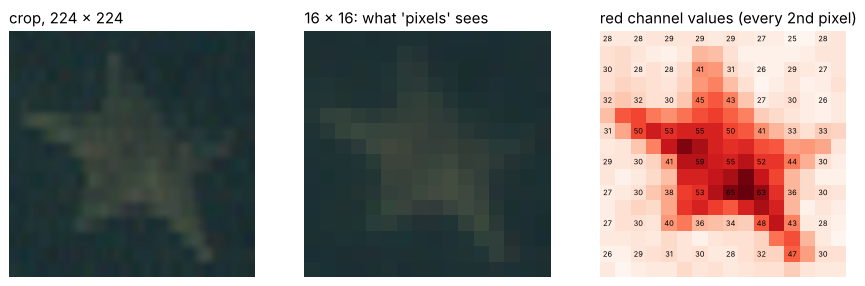

In [2]:
df = data.set_target(data.load_dataset(), "label")
row = df[df["label"] == "Hippasteria"].iloc[3]
im = Image.open(row["path"])
small = im.resize((16, 16), Image.BILINEAR)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(im); axes[0].set_title("crop, 224 × 224", loc="left")
axes[1].imshow(small); axes[1].set_title("16 × 16: what 'pixels' sees", loc="left")
red = np.asarray(small)[:, :, 0]
axes[2].imshow(red, cmap="Reds")
for (i, j), v in np.ndenumerate(red[::2, ::2]):
    axes[2].text(2 * j, 2 * i, v, ha="center", va="center", fontsize=6)
axes[2].set_title("red channel values (every 2nd pixel)", loc="left")
for a in axes: a.axis("off")

## 2. What a CNN does (in one paragraph)
A CNN slides thousands of small **filters** over the image. The first layers respond to edges and colour blobs,
middle layers to textures and repeated patterns (spines, tentacles, polyps), the last layers to whole object parts.
Trained on ImageNet (dogs, cars, mushrooms …), these filters are general enough to describe deep-sea animals too.
We cut off the network's last layer and keep the **512 numbers** before it: the *embedding*. We do **not** train
the CNN here – we only use it as a very good character extractor (*transfer learning*).

In [3]:
X = {"pixels": features.pixels(df),
     "colour_stats": features.colour_stats(df),
     "cnn": features.cnn_embedding(df)}          # cached in features_cache/ after the first run
{k: v.shape for k, v in X.items()}

{'pixels': (23664, 768), 'colour_stats': (23664, 30), 'cnn': (23664, 512)}

## 3. A map of the animals
Each feature set places every crop as a point in a space with 30–768 dimensions. **t-SNE** draws a 2-D map of that
space in which crops that are close in the feature space stay close on the map (distances between far-apart groups
mean little). Points are coloured by phylum. This takes about a minute per map.

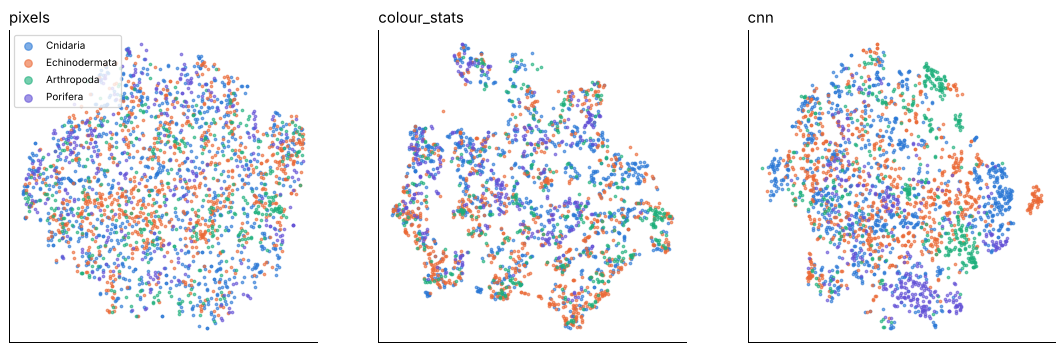

In [4]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
sample = df.sample(3000, random_state=0).index
phyla = df["phylum"].value_counts().index[:4]
cols = dict(zip(phyla, [evaluate.BLUE, evaluate.ORANGE, evaluate.AQUA, "#6250d6"]))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, F) in zip(axes, X.items()):
    Z = PCA(min(30, F.shape[1]), random_state=0).fit_transform(StandardScaler().fit_transform(F[sample]))
    P = TSNE(2, init="pca", random_state=0).fit_transform(Z)
    ph = df.loc[sample, "phylum"].to_numpy()
    for p in phyla:
        ax.scatter(*P[ph == p].T, s=4, c=cols[p], label=p, alpha=.6)
    ax.set_title(name, loc="left"); ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(markerscale=3, fontsize=8);

> ### ✍️ Q1
> In which map do the phyla form the clearest groups? What does that suggest about which features will work best? (A 2-D map loses information – a mixed-up map does not prove the features are useless.)

*Your answer:*

## 4. Nearest neighbours: 'which crops look most similar?'
For one query crop, show the 5 most similar crops in each feature space. Correct neighbours (same label) get a ✓.

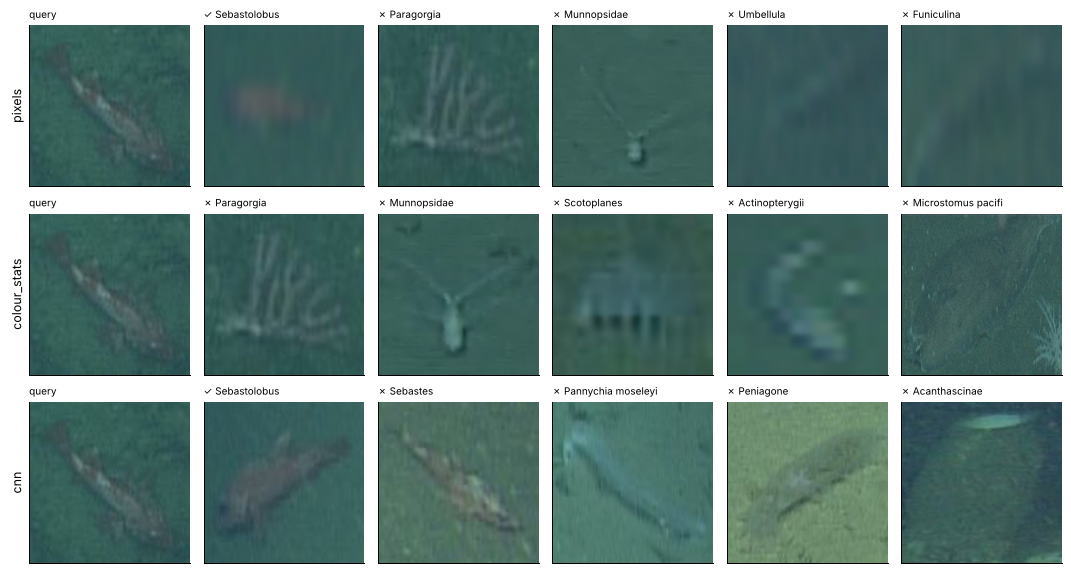

In [5]:
from sklearn.neighbors import NearestNeighbors
query = df[df["label"] == "Sebastolobus"].index[5]
fig, axes = plt.subplots(3, 6, figsize=(12, 6.5))
for r, (name, F) in enumerate(X.items()):
    Fs = StandardScaler().fit_transform(F)
    nn = NearestNeighbors(n_neighbors=6).fit(Fs)
    idx = nn.kneighbors(Fs[[query]], return_distance=False)[0]
    for c, i in enumerate(idx):
        ax = axes[r, c]; ax.imshow(Image.open(df.loc[i, "path"])); ax.set_xticks([]); ax.set_yticks([])
        ok = "query" if c == 0 else ("✓ " if df.loc[i, "label"] == df.loc[query, "label"] else "✗ ") + df.loc[i, "label"][:18]
        ax.set_title(ok, fontsize=8, loc="left")
    axes[r, 0].set_ylabel(name)
fig.tight_layout()

## 5. The classifier zoo
Seven classifiers × three feature sets, 79 labels, a random 75 / 25 split. This takes a few minutes (the random
forest and the neural network are the slowest). Each classifier is one line in `classifier_lab/models.py` – open it!

| name | idea |
|---|---|
| `majority` | always the most common label (baseline) |
| `nearest_centroid` | closest average crop |
| `knn` | vote of the 5 most similar training crops |
| `decision_tree` | learned identification key |
| `random_forest` | 300 randomised keys, majority vote |
| `logistic_regression` | a weighted checklist: score per label = sum of (weight × feature) |
| `mlp` | a small neural network: checklists of checklists |

In [6]:
train, test = data.split(df, "random", seed=0)
tr = df["annotation_id"].isin(train["annotation_id"]).to_numpy()
y = df["y"].to_numpy()
rows = []
for fname, F in X.items():
    for cname in models.NAMES:
        res, _ = evaluate.run(models.make(cname), F[tr], y[tr], F[~tr], y[~tr])
        rows.append({"features": fname, "classifier": cname, **res})
        print(f"{fname:13s} {cname:20s} test {res['accuracy']:.1%}   train {res['train_accuracy']:.1%}   {res['fit_seconds']:.0f}s")
zoo = pd.DataFrame(rows)
zoo.to_csv("results/lab2_zoo.csv", index=False) if Path("results").exists() else None

pixels        majority             test 1.3%   train 1.3%   0s


pixels        nearest_centroid     test 10.7%   train 10.9%   3s


pixels        knn                  test 23.0%   train 42.8%   0s


pixels        decision_tree        test 15.4%   train 100.0%   30s


pixels        random_forest        test 37.2%   train 100.0%   62s


pixels        logistic_regression  test 39.7%   train 58.1%   75s


... (10 outputs left out)

cnn           decision_tree        test 20.5%   train 100.0%   47s


cnn           random_forest        test 56.1%   train 100.0%   90s


cnn           logistic_regression  test 63.7%   train 90.7%   20s


cnn           mlp                  test 64.6%   train 92.4%   14s


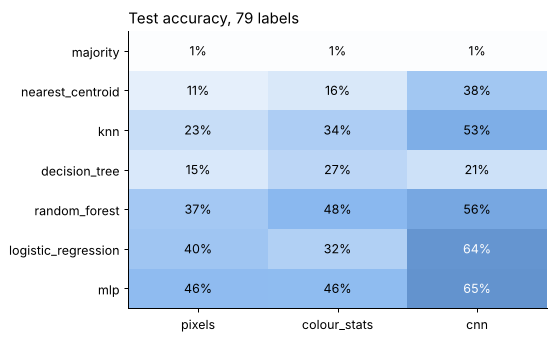

In [7]:
tab = zoo.pivot(index="classifier", columns="features", values="accuracy").loc[models.NAMES, ["pixels", "colour_stats", "cnn"]]
fig, ax = plt.subplots(figsize=(6, 4))
from matplotlib.colors import LinearSegmentedColormap
ax.imshow(tab.to_numpy(), cmap=LinearSegmentedColormap.from_list("b", ["#ffffff", "#86b6ef", "#104281"]), vmin=0, vmax=1,
          aspect="auto")
ax.set_xticks(range(3), tab.columns); ax.set_yticks(range(len(tab)), tab.index)
for (i, j), v in np.ndenumerate(tab.to_numpy()):
    ax.text(j, i, f"{v:.0%}", ha="center", va="center", color="white" if v > .6 else "black")
ax.set_title("Test accuracy, 79 labels", loc="left");

> ### ✍️ Q2
> Which matters more for accuracy: the choice of **features** or the choice of **classifier**? Support your answer with two numbers from the table.

*Your answer:*

> ### ✍️ Q3
> Compare train and test accuracy for `knn`, `decision_tree` and `random_forest` on CNN features (`zoo[zoo.features == 'cnn']`). Which ones overfit? Is overfitting always bad for the test accuracy?

*Your answer:*

> ### ✍️ Q4
> Logistic regression is a 'weighted checklist'. Why might such a simple rule work so well on CNN features but badly on raw pixels?

*Your answer:*

## 6. Your group
How well does the best combination do on the labels of *your* group (from Lab 0)?

In [8]:
MY_RANK, MY_GROUP = "class", "Asteroidea"        # <- your group
clf = models.make("logistic_regression").fit(X["cnn"][tr], y[tr])
pred = pd.Series(clf.predict(X["cnn"][~tr]), index=df.index[~tr])
mine = df.index[~tr][df.loc[~tr, MY_RANK] == MY_GROUP]
evaluate.per_label(df.loc[mine, "y"], pred[mine])

,recall,n
true,,
Asteroidea,0.520000,75
Brisingida,0.653333,75
Rathbunaster californicus,0.653333,75
Mediaster aequalis,0.702703,74
Hippasteria,0.786667,75


> ### ✍️ Q5
> Report the recall of each label of your group. Which label is hardest? Look at a few of its crops (Lab 0) – can you see why?

*Your answer:*